<a href="https://colab.research.google.com/github/kzubiya688/medical-insurance-cost-prediction/blob/main/Medical_Insurance_Cost_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


# load the dataset

In [2]:
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# display dataset

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


#Check dataset information

In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape:
(1338, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Statistical Summary:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


# check missing value

In [5]:
print("Missing Values:")

print(df.isnull().sum())

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 1


In [7]:
df.drop_duplicates(inplace=True)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Data visualization

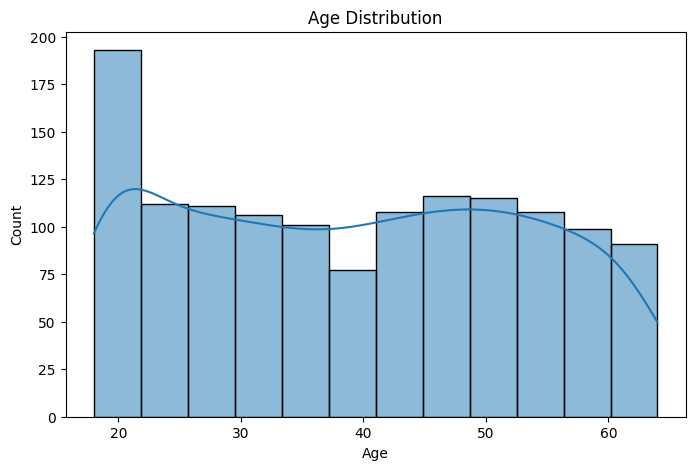

In [10]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

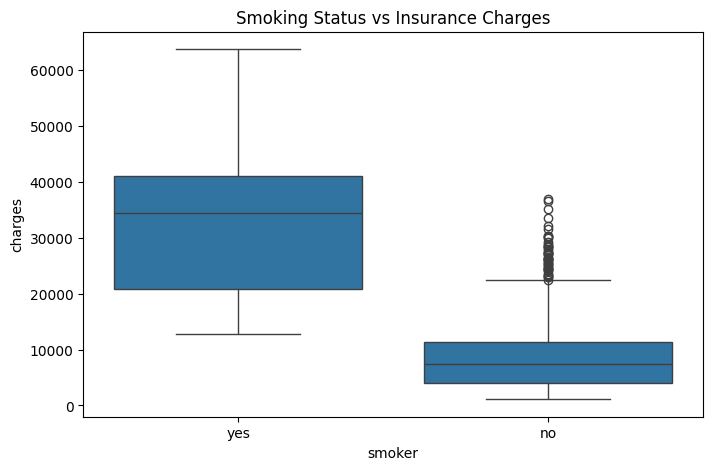

In [11]:
plt.figure(figsize=(8,5))

sns.boxplot(x='smoker', y='charges', data=df)

plt.title("Smoking Status vs Insurance Charges")

plt.show()

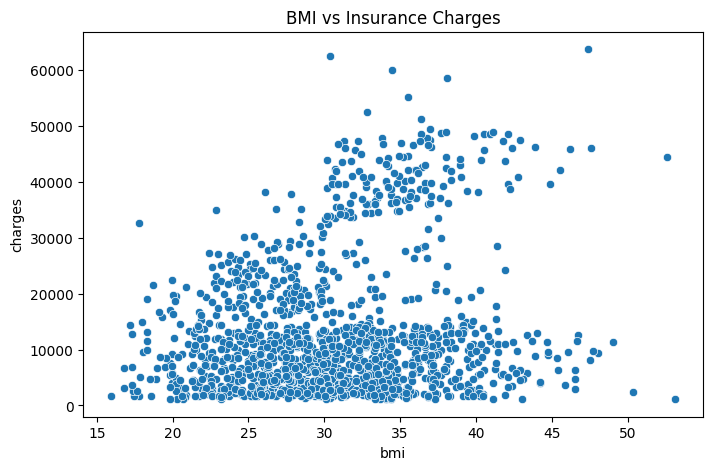

In [12]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    x='bmi',
    y='charges',
    data=df
)

plt.title("BMI vs Insurance Charges")

plt.show()

# Prepare data for machine learning

In [13]:
X = df.drop('charges', axis=1)

y = df['charges']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   age     sex     bmi  children smoker     region
0   19  female  27.900         0    yes  southwest
1   18    male  33.770         1     no  southeast
2   28    male  33.000         3     no  southeast
3   33    male  22.705         0     no  northwest
4   32    male  28.880         0     no  northwest

Target Values:
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64


# Convert categorical data

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_columns = ['sex', 'smoker', 'region']

preprocessor = ColumnTransformer(
    transformers=[
        ('encoder', OneHotEncoder(handle_unknown='ignore'),
         categorical_columns)
    ],
    remainder='passthrough'
)

X_encoded = preprocessor.fit_transform(X)

print("Categorical data converted successfully!")
print("New dataset shape:", X_encoded.shape)

Categorical data converted successfully!
New dataset shape: (1337, 11)


# Split the dataset

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1069, 11)
Testing data: (268, 11)


# Train the Linear Regression model

In [16]:
from sklearn.linear_model import LinearRegression

_
model = LinearRegression()

model.fit(X_train, y_train)
y_pred = model.predict(X_test)


print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


# Evaluate the model

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")

print("MAE:", mae)

print("MSE:", mse)

print("R2 Score:", r2)

Model Evaluation Results
MAE: 4177.045561036321
MSE: 35478020.67523553
R2 Score: 0.8069287081198016


# Actual vs predicted graph

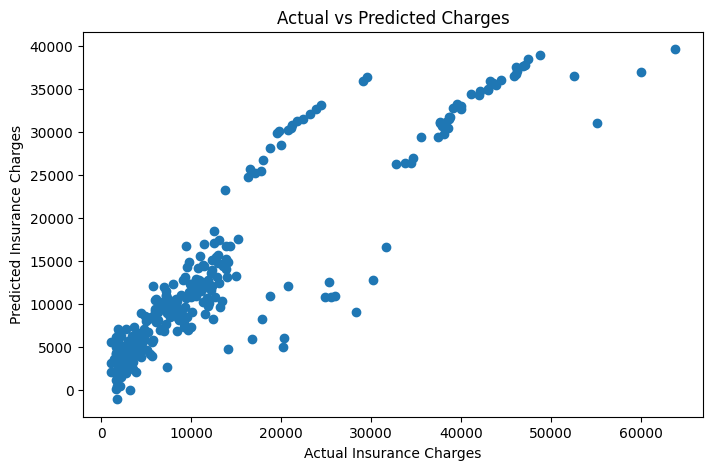

In [18]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Insurance Charges")

plt.ylabel("Predicted Insurance Charges")

plt.title("Actual vs Predicted Charges")

plt.show()

# Save your trained model

In [19]:
import pickle
with open('model.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [20]:

import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Select features
X = df[['age', 'sex', 'bmi', 'children',
        'smoker', 'region']]

# Select target
y = df['charges']

# Categorical and numerical columns
categorical = ['sex', 'smoker', 'region']
numerical = ['age', 'bmi', 'children']

# Preprocessing
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'),
     categorical)
], remainder='passthrough')

# Create model pipeline
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model.fit(X_train, y_train)

# Evaluate model
predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

# Train on all data for deployment
model.fit(X, y)

# Save model using pickle
with open('model.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model saved successfully!")


MAE: 4177.045561036321
R2 Score: 0.8069287081198016
Model saved successfully!


In [21]:
from google .colab import files
files.download('model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
!pip install -q streamlit

import streamlit as st
import pickle

# Load trained model
with open('model.pkl', 'rb') as file:
    model = pickle.load(file)

st.title("Medical Insurance Cost Prediction")

st.success("Model loaded successfully!")

2026-11-27 20:31:12.524 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-27 20:31:12.762 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-27 20:31:12.763 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-27 20:31:12.764 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-27 20:31:12.765 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-27 20:31:12.766 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-27 20:31:12.766 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()